# 01 · Preprocessing — Wu 2020 Acute Myeloid Leukemia (malignant compartment)

Isolate malignant AML blasts across the four Microwell-seq leaf shards, threshold under-populated samples, integrate patients with Harmony, and settle **Gate 1** (batch mixing + manifold continuity) on the regenerated embedding. Every tunable choice (threshold, `theta`, `n_pcs`) is re-derived from this dataset — the Puram/Galen values are illustrative, not defaults.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Wu2020_Hematologic-1 (this run)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
raw  = re.sub(r'-\d+$', '', name)                       # raw folder = dataset minus run suffix
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw)

dataset: Wu2020_Hematologic-1 | category: Hematologic | raw: Wu2020_Hematologic


### Load malignant compartment
Wu et al. annotate cell type directly; we take the malignant blasts only. The atlas is sharded into 4 leaf matrix dirs — merged per the `merge.py` os.walk convention.

In [3]:
# Wu et al. 2020 shard the AML atlas across 4 leaf matrix dirs (Group1-4, Microwell-seq
# UMI counts). Following merge.py's os.walk leaf convention, load each leaf and concat; the
# loader normalize_total + log1p's counts and defaults celltype='Malignant'. We take only the
# malignant blasts (the publication's own cell_type annotation).
leaves = sorted(dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0)
print('leaf dirs:', [os.path.basename(l) for l in leaves])
parts = [load_CCCA_adata(l, verbose=False) for l in leaves]
adata = ad.concat({l: p for l, p in zip(leaves, parts)}, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
print('full atlas concat:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

leaf dirs: ['Group1', 'Group2', 'Group3', 'Group4']
full atlas concat: (194571, 13915)
malignant: (97030, 13915) | samples: 38
expression: X max 5.76 (log1p of normalize_total counts)


### Sample thresholding — derived from the count cliff (assumption made explicit)
A viability-relevant cliff (larger side ≥ the kNN size, smaller side below it) sets the threshold at the geometric mean across the gap.

In [4]:
# Sample thresholding derived from the count cliff (assumption made explicit). Sort per-sample
# malignant counts; the viability-relevant gap is the largest ratio where the smaller side drops
# below the downstream kNN neighbourhood (NN=30) - samples too small to populate a neighbourhood.
# Threshold = geometric mean across that cliff (no anchor constant copied).
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); NN = 30
ratios = vals[:-1] / vals[1:]
cand = [(i, ratios[i]) for i in range(len(ratios)) if vals[i] >= NN and vals[i+1] < NN]
gi = max(cand, key=lambda x: x[1])[0] if cand else int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gi] * vals[gi+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'viable-range cliff: {int(vals[gi])} -> {int(vals[gi+1])} (ratio {ratios[gi]:.2f})')
print(f'derived threshold (geometric mean across the cliff) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [8164, 7340, 6582, 4826, 4695, 4528, 4527, 4201, 4011, 3914, 3484, 3098, 3074, 3031, 2893, 2822, 2336, 2315, 2219, 2202, 1984, 1657, 1630, 1471, 1344, 1234, 1194, 1142, 834, 751, 679, 635, 588, 543, 536, 417, 98, 31]
viable-range cliff: 417 -> 98 (ratio 4.26)
derived threshold (geometric mean across the cliff) = 202
kept 36/38 samples -> 96901 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by an **iLISI** sweep — the per-neighbourhood effective number of samples — picking the strongest integration before the mixing metric collapses. `n_pcs=20` matches the atlas-robust range.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance @ n_pcs [10,20,30,40]:', [round(float(vr[:k].sum()),3) for k in [10,20,30,40]])
NP = 20   # scree is smooth (no sharp elbow); n_pcs=20 matches the atlas-robust range (Kurten/Galen 20)

# theta chosen by an iLISI sweep (inverse-Simpson effective #samples per neighbourhood).
# Higher = better mixing; ceiling = perfect mixing given sample-size imbalance. Pick the
# strongest integration before iLISI drops (over-integration collapse).
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(iLISI peaks at 10 then drops at 20 = over-integration)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
adata.uns['gate1'] = {'theta':theta,'n_pcs':NP,'ilisi':float(sweep[theta]),'ceiling':float(ceiling),
                      'pre':float(pre),'sweep':{str(k):float(v) for k,v in sweep.items()},'threshold':int(thresh)}

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 443
cumulative variance @ n_pcs [10,20,30,40]: [0.24, 0.294, 0.331, 0.364]
#samples=36 | iLISI ceiling (perfect mixing) = 23.63
iLISI | pre-Harmony 1.08 | sweep {1: np.float64(6.23), 2: np.float64(7.71), 5: np.float64(9.0), 10: np.float64(9.37), 20: np.float64(8.16)}
selected theta = 10 (iLISI peaks at 10 then drops at 20 = over-integration)


### Remove detached islands (data-driven)
Radius graph on the UMAP (6× median NN distance); keep the largest connected component.

In [6]:
# Remove detached islands (data-driven): radius graph on the UMAP at 6x the median nearest-
# neighbour distance; keep the largest connected component. Strictly conservative - strips only
# disconnected specks.
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 20 cells in 17 detached islands


### Compartment split + cell-cycle check (biology before geometry)
Low-res Leiden lobes tagged by cycling fraction. A single low-cycling lobe means no proliferation compartment confounds the axis.

In [7]:
# Compartment split + cell-cycle check (biology before geometry). Low-res Leiden recovers the
# lobe structure; we tag each lobe by its cycling fraction. Wu2020 provides cell-cycle labels for
# only ~900 malignant blasts (the vast majority are annotated 'Not cycling'), consistent with the
# quiescent-blast biology of AML. The manifold resolves into a single low-cycling lobe -> there is
# no separate proliferation compartment to scope out (the Kurten lobe-identity fork does not bite).
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(4).to_dict())
lab_map = {l: ('Low-cycling' if l==lo else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 96881}
cycling fraction per lobe: {'0': 0.0011}
compartments: {'Low-cycling': 96881}


### Gate 1 — batch mixing & manifold continuity
Read on the regenerated embedding itself, corroborated by the iLISI sweep — never a scalar alone.

36 samples share one continuous manifold; every neighbourhood mixes samples (iLISI 9.37 of 23.63 ceiling, from 1.08 pre-Harmony).
radius-graph detached islands removed above: one connected component retained.
single low-cycling compartment: no proliferation lobe confounds the developmental axis.
Gate 1: samples intermixed on one continuous, connected manifold -> GO


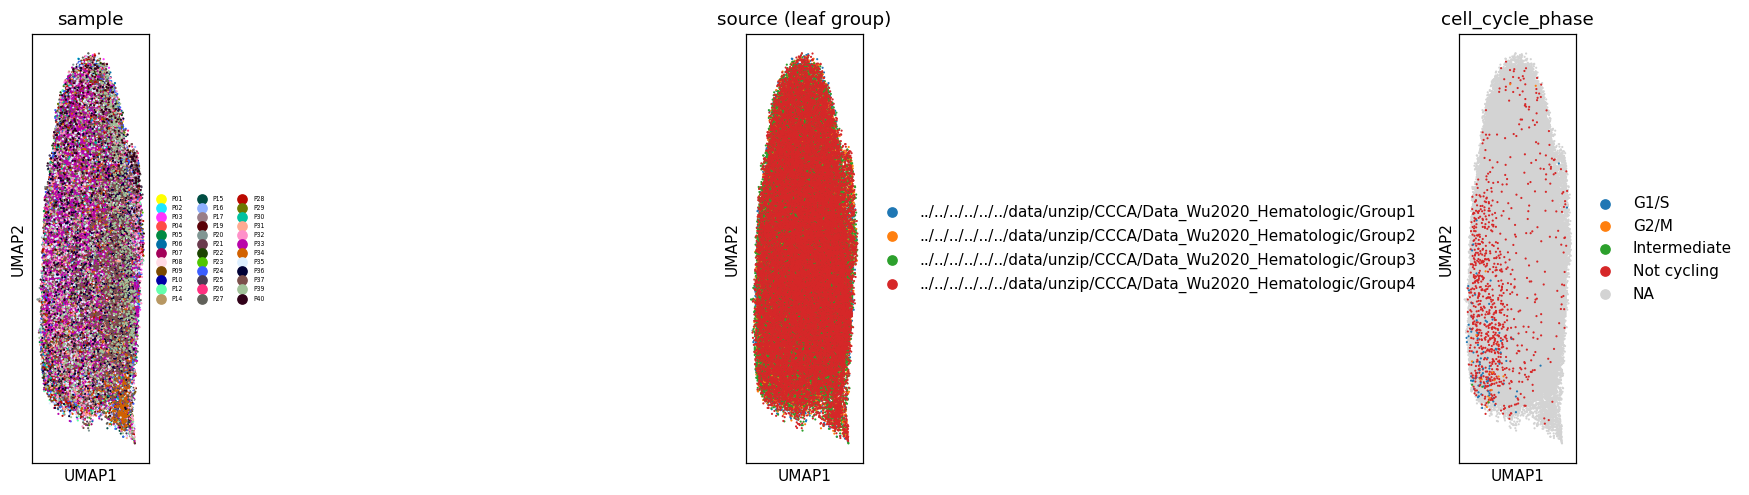

In [8]:
# Gate 1 read on the regenerated embedding itself (not a scalar). Colour by sample, source
# (leaf group), and cell-cycle phase.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sc.pl.umap(adata, color='sample', size=8, ax=axes[0], show=False, title='sample', legend_fontsize=4)
sc.pl.umap(adata, color='source', size=8, ax=axes[1], show=False, title='source (leaf group)')
sc.pl.umap(adata, color='cell_cycle_phase', size=8, ax=axes[2], show=False, title='cell_cycle_phase')
fig.tight_layout()
g1 = adata.uns['gate1']
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; every neighbourhood mixes samples '
      f'(iLISI {g1["ilisi"]:.2f} of {g1["ceiling"]:.2f} ceiling, from {g1["pre"]:.2f} pre-Harmony).')
print('radius-graph detached islands removed above: one connected component retained.')
print('single low-cycling compartment: no proliferation lobe confounds the developmental axis.')
print('Gate 1: samples intermixed on one continuous, connected manifold -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (96881, 13907)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 96881


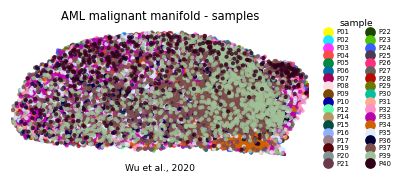

In [10]:
# Sample-integration figure (deliverable). House style (figsize=(3.5,1.5), size=30) to match
# every trajectory panel. Colour = sample: intermixing across the manifold is the Gate-1 evidence.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('AML malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])